# EcoDrive — 01 · Cadrage et analyse des données
**Équipe :** Enzo BASLY, Guillaume, Rayan

**Décision à éclairer :** chaque lundi, le gestionnaire de flotte décide (1) quels véhicules envoyer en contrôle
parce qu'ils consomment anormalement et (2) quels conducteurs inscrire à une formation éco-conduite.

**Problématique (régression supervisée) :** prédire la consommation « normale » d'un trajet (L/100 km) à partir
du trajet, des conditions et du véhicule. On s'en sert ensuite pour (1) alerter quand la conso réelle dépasse
nettement la prévision et (2) comparer les styles de conduite.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config import DATA, FIG, TARGET, NUM_FEATURES, EXCLUES
from modeles import sauver

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA)
print(df.shape)
df.head()

(21105, 23)


,veh_id,trip_id,jour,duree_min,distance_km,vitesse_moy,vitesse_max,vitesse_std,part_arret,part_autoroute,...,rpm_moy,temp_ext,rpa,arrets_par_km,conso_l100,type_vehicule,classe,cylindree_l,poids_kg,transmission_roues
0,366,3227,359.976264,2.0,1.191667,35.750000,68.0,25.657895,0.324167,0.0,...,1191.680000,8.52,0.226138,0.839161,12.452238,ICE,NaN,3.5,2041.2,NaN
1,344,1065,37.966253,2.0,1.206361,36.190833,63.0,23.607727,0.273333,0.0,...,1263.408333,NaN,0.201373,0.828939,7.013417,HEV,NaN,2.3,1587.6,NaN
2,185,1951,64.693498,2.0,1.674250,50.227500,59.0,7.850210,0.000000,0.0,...,1818.074167,NaN,0.137476,0.000000,7.730284,ICE,NaN,1.5,1134.0,NaN
3,156,1871,290.487705,2.0,1.489750,44.692500,74.0,23.183605,0.058333,0.0,...,1366.097500,NaN,0.251567,1.342507,10.754608,ICE,NaN,3.5,2041.2,NaN
4,351,1220,124.900131,2.0,1.033861,31.015833,51.0,12.220783,0.041667,0.0,...,516.088333,4.00,0.252682,1.934496,4.028120,HEV,NaN,1.8,1360.8,NaN


## 1. Description
Source : Vehicle Energy Dataset (VED), Oh, LeBlanc & Peng (2020), https://github.com/gsoh/VED, licence Apache 2.0.
Les mesures capteurs ont été agrégées par trajet (`src/prepare_trips.py`) : **1 ligne = 1 trajet**.

In [2]:
pd.DataFrame({
    "variable": ["duree_min", "distance_km", "vitesse_moy / max / std", "part_arret", "part_autoroute",
                 "part_accel_forte / part_freinage_fort", "accel_moy_pos", "rpm_moy", "temp_ext", "rpa",
                 "arrets_par_km", "cylindree_l, poids_kg, type_vehicule, classe", "conso_l100"],
    "unité": ["min", "km", "km/h", "%", "%", "%", "m/s²", "tr/min", "°C", "m/s²", "1/km", "L, kg, -", "L/100 km"],
    "signification": ["durée", "distance", "vitesse", "temps < 3 km/h", "temps > 90 km/h",
                      "temps en accél. > 1,5 m/s² / freinage < -2 m/s²", "accélération moyenne quand on accélère",
                      "régime moteur moyen", "température extérieure", "énergie d'accélération par mètre (construite)",
                      "redémarrages par km (construite)", "véhicule", "CIBLE"]})

,variable,unité,signification
0,duree_min,min,durée
1,distance_km,km,distance
2,vitesse_moy / max / std,km/h,vitesse
3,part_arret,%,temps < 3 km/h
4,part_autoroute,%,temps > 90 km/h
5,part_accel_forte / part_freinage_fort,%,"temps en accél. > 1,5 m/s² / freinage < -2 m/s²"
6,accel_moy_pos,m/s²,accélération moyenne quand on accélère
7,rpm_moy,tr/min,régime moteur moyen
8,temp_ext,°C,température extérieure
9,rpa,m/s²,énergie d'accélération par mètre (construite)


## 2. Qualité

In [3]:
print("doublons :", df.duplicated(["veh_id", "trip_id"]).sum())
q = df.isna().mean().mul(100).round(1)
q[q > 0]

doublons : 0


temp_ext               51.3
classe                 98.9
poids_kg                2.6
transmission_roues    100.0
dtype: float64

**Constat :** seule `temp_ext` a des manquants (capteur absent). **Décision :** imputation par la médiane dans le
pipeline (ajustée sur le train uniquement). Les trajets < 1 km, < 2 min, sans signal carburant fiable ou avec une
conso impossible ont été retirés dans `prepare_trips.py`.

In [4]:
sauver("donnees", {"n_trajets": len(df), "n_vehicules": int(df.veh_id.nunique()), "n_colonnes": df.shape[1],
                   "pct_temp_manquante": float(df.temp_ext.isna().mean() * 100),
                   "n_ice": int((df.type_vehicule == "ICE").sum()), "n_hev": int((df.type_vehicule == "HEV").sum()),
                   "conso_moy": float(df[TARGET].mean())})

## 3. La cible

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df, x=TARGET, hue="type_vehicule", bins=50, ax=ax[0])
ax[0].set(title="Distribution de la consommation par trajet", xlabel="L/100 km", ylabel="nb trajets")
sns.boxplot(df, x="classe", y=TARGET, hue="type_vehicule", ax=ax[1])
ax[1].set(title="Consommation selon le véhicule", xlabel="", ylabel="L/100 km")
plt.tight_layout(); plt.savefig(FIG / "01_cible.png", bbox_inches="tight"); plt.show()

<Figure size 1210x418 with 2 Axes>

**Lecture :** deux populations (hybrides / thermiques) et une queue à droite. Variable continue, connue sur tout
l'historique → **régression**. Le type de véhicule doit être une variable explicative.

## 4. Relations avec la cible

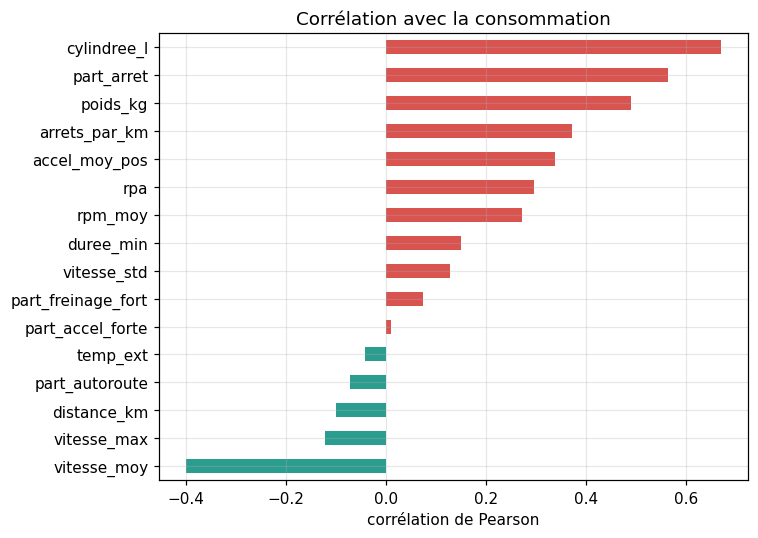

In [6]:
corr = df[NUM_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "#d9534f", "#2a9d8f"))
ax.set(title="Corrélation avec la consommation", xlabel="corrélation de Pearson")
plt.tight_layout(); plt.savefig(FIG / "01_correlations.png", bbox_inches="tight"); plt.show()

**Lecture :** le véhicule (cylindrée, poids) domine, puis le régime moteur et les accélérations fortes.

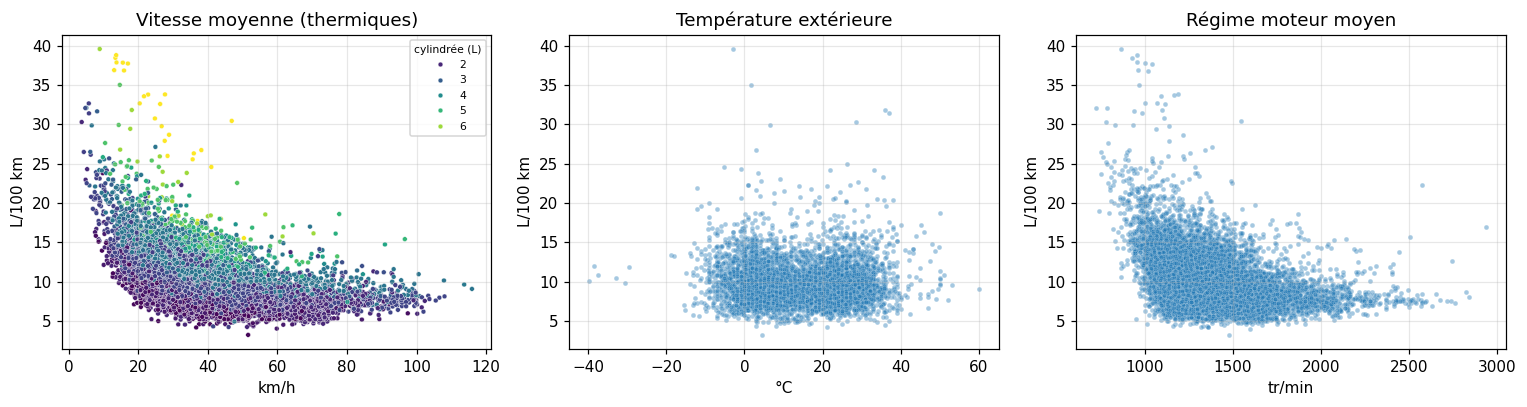

In [7]:
ice = df[df.type_vehicule == "ICE"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.scatterplot(ice, x="vitesse_moy", y=TARGET, hue="cylindree_l", s=10, ax=ax[0], palette="viridis")
ax[0].legend(title="cylindrée (L)", fontsize=7, title_fontsize=7, loc="upper right")
ax[0].set(title="Vitesse moyenne (thermiques)", xlabel="km/h", ylabel="L/100 km")
sns.scatterplot(ice, x="temp_ext", y=TARGET, s=10, alpha=.4, ax=ax[1])
ax[1].set(title="Température extérieure", xlabel="°C", ylabel="L/100 km")
sns.scatterplot(ice, x="rpm_moy", y=TARGET, s=10, alpha=.4, ax=ax[2])
ax[2].set(title="Régime moteur moyen", xlabel="tr/min", ylabel="L/100 km")
plt.tight_layout(); plt.savefig(FIG / "01_relations.png", bbox_inches="tight"); plt.show()

**Lecture :** effet non linéaire de la vitesse (ville et autoroute coûtent plus que le mixte), effet du froid et du
régime : un modèle à arbres devrait faire mieux qu'un modèle linéaire.

## 5. Audit de fuite

In [8]:
pd.DataFrame({"variable écartée": list(EXCLUES), "raison": list(EXCLUES.values())})

,variable écartée,raison
0,"MAF, Fuel Rate",servent à CALCULER la cible : les garder = don...
1,"Absolute Load, Fuel Trims",charge moteur et corrections d'injection ≈ déb...
2,"veh_id, trip_id",identifiants : le modèle apprendrait un véhicu...
3,jour,sert uniquement au découpage chronologique tra...


## 6. Variables construites
- **rpa** = Σ(v·a⁺)·dt / distance : énergie dépensée à accélérer par mètre (indicateur classique d'éco-conduite).
- **arrets_par_km** : chaque redémarrage relance 1,5 t de voiture.

**Conséquences :** split **chronologique**, pipeline scikit-learn, MAE en L/100 km comme métrique principale.